In [20]:
# ============================================================
# PHENOSENSING - EXPLORATION 1
# Analyse phénologique spatialement implicite
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import phenosensing
import pandas as pd

from phenosensing import load_sample



# ------------------------------------------------------------
# 1. Import dataset
# ------------------------------------------------------------

pheno_RN = pd.read_csv("../data/NDVI_modis_RN_2016_2026.csv")


In [29]:
# ------------------------------------------------------------
# 2. Préparer la série temporelle
# ------------------------------------------------------------

pheno_RN["date"] = pd.to_datetime(pheno_RN["date"])

pheno_RN = pheno_RN.sort_values("date")

# Ajouter année et jour de l'année
pheno_RN["year"] = pheno_RN["date"].dt.year
pheno_RN["doy"] = pheno_RN["date"].dt.dayofyear

# Garder uniquement 2016–2025
pheno_RN = pheno_RN[
    pheno_RN["date"].dt.year <= 2025
].copy()

In [30]:
# ------------------------------------------------------------
# 3. Créer un xarray.DataArray
# ------------------------------------------------------------

ts = xr.DataArray(
    pheno_RN["mean_ndvi"].values,
    coords={
        "time": pheno_RN["date"].values,
        "year": ("time", pheno_RN["year"].values),
        "doy": ("time", pheno_RN["doy"].values),
    },
    dims=["time"],
    name="NDVI"
)

In [31]:
# ============================================================
# 5. PHÉNOLOGIE ANNÉE PAR ANNÉE
# ============================================================

phenology_curves = {}
lsp_results = {}


for year in sorted(pheno_RN["year"].unique()):

    print(f"\n================ {year} ================")

    # --------------------------------------------------------
    # Extraire une année
    # --------------------------------------------------------

    ts_year = ts.where(
        ts.year == year,
        drop=True
    )

    print(
        f"Nombre d'observations : {ts_year.time.size}"
    )

    # --------------------------------------------------------
    # Reconstruction
    # --------------------------------------------------------

    shape = ts_year.pheno.PhenoShape(
        interpolType="whittaker",
        rollWindow=5,
        nGS=52
    )

    phenology_curves[year] = shape

    # --------------------------------------------------------
    # Extraction LSP
    # --------------------------------------------------------

    lsp = shape.pheno.PhenoLSP()

    lsp_results[year] = lsp

    print(lsp)


================ 2016 ================
Nombre d'observations : 152
<xarray.Dataset> Size: 144B
Dimensions:  ()
Data variables: (12/18)
    sos      float64 8B 113.0
    pos      float64 8B 169.0
    eos      float64 8B 281.0
    vsos     float64 8B 0.6665
    vpos     float64 8B 0.8067
    veos     float64 8B 0.7411
    ...       ...
    ios      float64 8B 117.6
    rog      float64 8B 0.002504
    ros      float64 8B -0.0005861
    sw       float64 8B 0.02701
    trough   float64 8B 0.5458
    mos      float64 8B 197.0

================ 2017 ================
Nombre d'observations : 172
<xarray.Dataset> Size: 144B
Dimensions:  ()
Data variables: (12/18)
    sos      float64 8B 106.0
    pos      float64 8B 162.0
    eos      float64 8B 253.0
    vsos     float64 8B 0.6832
    vpos     float64 8B 0.809
    veos     float64 8B 0.7359
    ...       ...
    ios      float64 8B 102.9
    rog      float64 8B 0.002246
    ros      float64 8B -0.0008031
    sw       float64 8B -0.3711
    tr

In [28]:
type(lsp_results)
type(phenology_curves)

dict

## plot des phenos annuelles

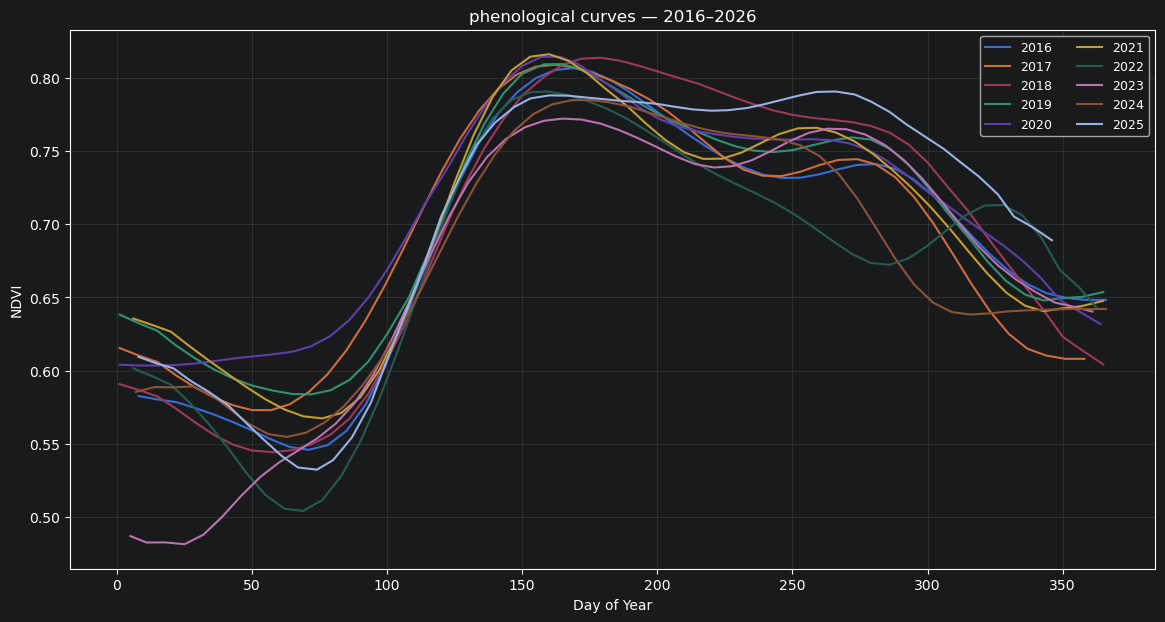

In [33]:
plt.figure(figsize=(14, 7))

for year, curve in phenology_curves.items():

    plt.plot(
        curve.doy,
        curve,
        label=str(year)
    )

plt.xlabel("Day of Year")
plt.ylabel("NDVI")
plt.title("phenological curves — 2016–2026")

plt.legend(
    ncol=2,
    fontsize=9
)

plt.grid(alpha=0.2)

plt.show()

# variations des metriques ?

In [34]:
# ============================================================
# 7. Extraire SOS / POS / EOS / LOS
# ============================================================

results = []

for year, lsp in lsp_results.items():

    row = {
        "year": year
    }

    for metric in [
        "sos",
        "pos",
        "eos",
        "los",
        "amplitude"
    ]:

        if metric in lsp:
            row[metric] = float(lsp[metric].values)

    results.append(row)


phenology_df = pd.DataFrame(results)

print("\nRésultats :")
print(phenology_df)


Résultats :
   year    sos    pos    eos    los
0  2016  113.0  169.0  281.0  168.0
1  2017  106.0  162.0  253.0  147.0
2  2018  115.0  179.0  272.0  157.0
3  2019  115.0  165.0  236.0  121.0
4  2020   86.0  164.0  264.0  178.0
5  2021  111.0  160.0  266.0  155.0
6  2022  111.0  160.0  237.0  126.0
7  2023   88.0  165.0  284.0  196.0
8  2024  105.0  175.0  246.0  141.0
9  2025  133.0  266.0  306.0  173.0


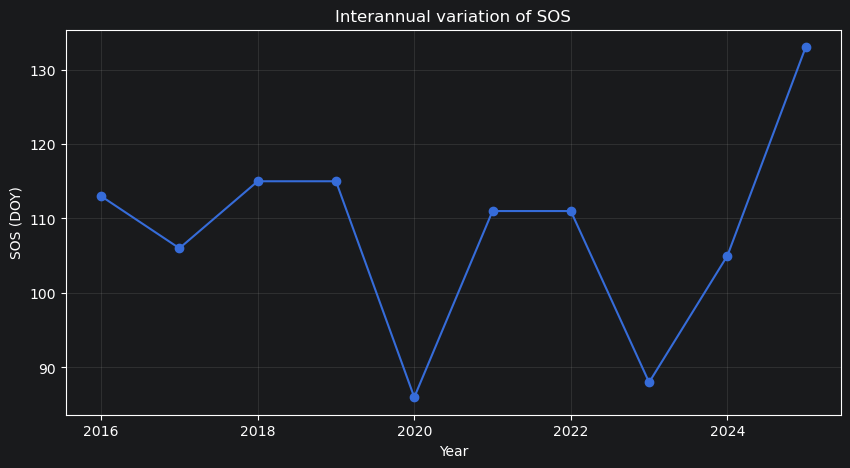

In [35]:
plt.figure(figsize=(10, 5))

plt.plot(
    phenology_df["year"],
    phenology_df["sos"],
    marker="o"
)

plt.xlabel("Year")
plt.ylabel("SOS (DOY)")
plt.title("Interannual variation of SOS")

plt.grid(alpha=0.2)

plt.show()

lien avec années de floraisons ?

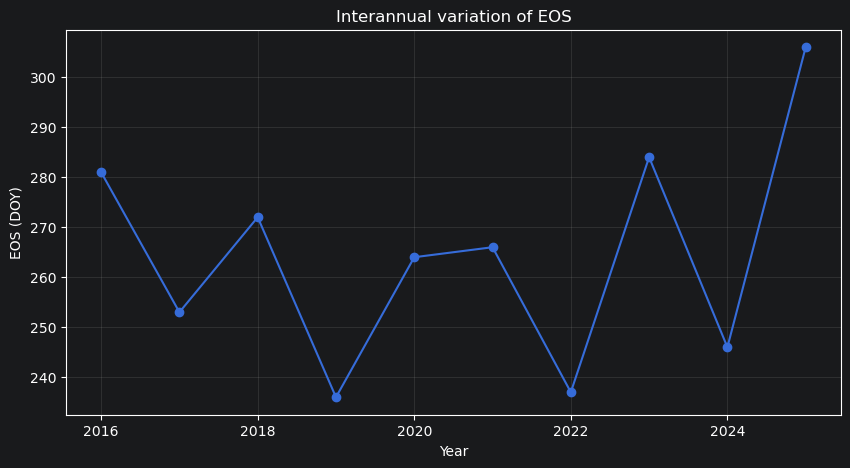

In [36]:
plt.figure(figsize=(10, 5))

plt.plot(
    phenology_df["year"],
    phenology_df["eos"],
    marker="o"
)

plt.xlabel("Year")
plt.ylabel("EOS (DOY)")
plt.title("Interannual variation of EOS")

plt.grid(alpha=0.2)

plt.show()

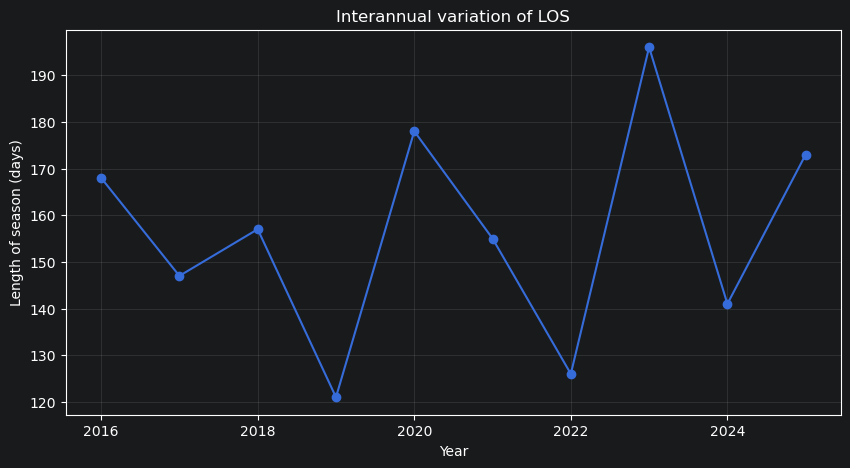

In [37]:
plt.figure(figsize=(10, 5))

plt.plot(
    phenology_df["year"],
    phenology_df["los"],
    marker="o"
)

plt.xlabel("Year")
plt.ylabel("Length of season (days)")
plt.title("Interannual variation of LOS")

plt.grid(alpha=0.2)

plt.show()